# Encore: the registry in numbers

Every number and figure a paper on the registry would cite, computed from the registry's own files at one commit.
The counts follow the site's rules (`tools/build_site.py`): an attempt that was deprecated counts for nothing, a
dataset's current attempt is its latest on each paper, and the paper's findings that rest on the dataset alone are
counted apart from those that also use data from elsewhere and from the registry's checks that the dataset is the
paper's data.

Not here yet: the human validation of a sample of outcomes and findings, run-to-run reliability, and the cost
of a run (in the Actions logs, not in the records).

In [1]:
import collections, json, subprocess, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "manuscript" else Path.cwd()
sys.path.insert(0, str(ROOT / "tools"))
import build_site as bs  # noqa: E402

data = bs.finish(bs.collect())
git = lambda *a: subprocess.run(["git", *a], cwd=ROOT, capture_output=True, text=True).stdout.strip()
COMMIT, WHEN = git("rev-parse", "--short", "HEAD"), git("log", "-1", "--format=%cI")
OUT = ROOT / "manuscript" / "out"
OUT.mkdir(exist_ok=True)
numbers = {"commit": COMMIT, "date": WHEN}
ORDER = ["reproduced", "partially_reproduced", "not_reproduced", "blocked"]
LABEL = {k: v[0] for k, v in bs.OUTCOMES.items()}
COLOUR = {"reproduced": "#0ca30c", "partially_reproduced": "#fab219", "not_reproduced": "#d03b3b", "blocked": "#898781"}
pct = lambda a, b: f"{100 * a / b:.0f}%" if b else "n/a"
print(f"Registry at {COMMIT}, committed {WHEN}")

Registry at abc0e2880, committed 2026-10-22T21:09:02-04:00


## 1. The sample

In [2]:
targets = data["targets"]
attempts = data["attempts"]
current = bs.current_attempts(data)
live = [a for v in current.values() for a in v if not a.get("deprecated")]
cn = {t["key"] for t in targets if t["catalystneuro"]}
attempted = {a["key"] for a in live}
sample = {
    "targets (public datasets that name a paper)": len(targets),
    "  of them converted by CatalystNeuro": len(cn),
    "datasets with a current attempt": len(attempted),
    "  of them converted by CatalystNeuro": len(attempted & cn),
    "papers attempted (dataset, paper pairs)": len(live),
    "attempt records in all": len(attempts),
    "  deprecated": sum(1 for a in attempts if a.get("deprecated")),
    "  repeat attempts (a dataset's second or later)": len(attempts) - len({(a["key"], a["paper"]) for a in attempts}),
}
numbers["sample"] = sample
pd.Series(sample, name="count").to_frame()

,count
targets (public datasets that name a paper),288
of them converted by CatalystNeuro,44
datasets with a current attempt,68
"papers attempted (dataset, paper pairs)",68
attempt records in all,79
deprecated,9
repeat attempts (a dataset's second or later),9


CatalystNeuro's conversions were attempted first, so the attempted set is not a random sample of the targets:
report the two groups apart (section 3), or attempt a random sample of the rest before freezing.

## 2. Outcomes of the claims

In [3]:
GROUPS = {"dataset": "Findings on the dataset alone", "with_inputs": "Findings that also use outside data",
          "elsewhere": "Findings on data in another archive", "link": "Checks that the dataset is the paper's data"}
rows = []
for g, name in GROUPS.items():
    c = bs.outcome_counts(live, g)
    n = sum(c.values())
    if n:
        rows.append({"claims": name, "n": n, **{LABEL[k]: f"{c[k]} ({pct(c[k], n)})" for k in ORDER}})
numbers["outcomes"] = {g: bs.outcome_counts(live, g) for g in GROUPS}
pd.DataFrame(rows).set_index("claims")

,n,Reproduced,Partially reproduced,Not reproduced,Blocked
claims,,,,,
Findings on the dataset alone,1640,537 (33%),271 (17%),240 (15%),592 (36%)
Findings that also use outside data,35,20 (57%),3 (9%),1 (3%),11 (31%)
Findings on data in another archive,81,40 (49%),10 (12%),2 (2%),29 (36%)
Checks that the dataset is the paper's data,31,19 (61%),8 (26%),4 (13%),0 (0%)


In [4]:
c = numbers["outcomes"]["dataset"]
tested = c["reproduced"] + c["partially_reproduced"] + c["not_reproduced"]
numbers["of_tested"] = {k: c[k] / tested for k in ORDER[:3]}
print(f"Of the {sum(c.values())} findings that rest on the dataset alone, {tested} could be tested "
      f"({pct(tested, sum(c.values()))}); {c['blocked']} were blocked.")
print(f"Of those tested: {pct(c['reproduced'], tested)} reproduced, {pct(c['partially_reproduced'], tested)} "
      f"partially, {pct(c['not_reproduced'], tested)} not reproduced.")

Of the 1640 findings that rest on the dataset alone, 1048 could be tested (64%); 592 were blocked.
Of those tested: 51% reproduced, 26% partially, 23% not reproduced.


### Why claims were blocked

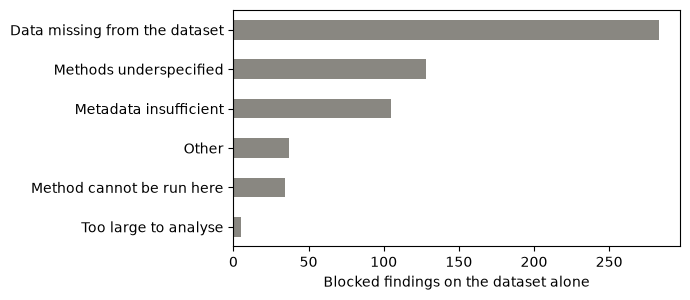

,claims
Data missing from the dataset,283
Methods underspecified,128
Metadata insufficient,105
Other,37
Method cannot be run here,34
Too large to analyse,5


In [5]:
blocked = collections.Counter(o["blocked_by"] or "unstated" for a in live for o in a["outcomes"]
                              if o["outcome"] == "blocked" and o.get("kind") != "link"
                              and o.get("data") in (None, "dataset", "with_labels"))
numbers["blocked_by"] = dict(blocked)
s = pd.Series({bs.BLOCKED_BY.get(k, k): v for k, v in blocked.most_common()}, name="claims")
ax = s.iloc[::-1].plot.barh(color="#898781", figsize=(7, 0.35 * len(s) + 1))
ax.set_xlabel("Blocked findings on the dataset alone"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(OUT / "blocked_by.png", dpi=200); plt.show()
s.to_frame()

## 3. By dataset

In [6]:
per = []
for a in live:
    c = bs.outcome_counts(a, "dataset")
    n = sum(c.values())
    if n:
        per.append({"dataset": a["label"], "paper": a.get("paper_title") or a["paper"], "n": n,
                    "catalystneuro": a["key"] in cn, "tier": a["tier"], "findings_about_data": len(a["findings"]),
                    **{k: c[k] for k in ORDER}})
per = pd.DataFrame(per)
per["reproduced_of_tested"] = per["reproduced"] / (per[ORDER[:3]].sum(axis=1)).replace(0, float("nan"))
per.to_csv(OUT / "per_dataset.csv", index=False)
per[["n"] + ORDER + ["findings_about_data"]].describe().round(1)

,n,reproduced,partially_reproduced,not_reproduced,blocked,findings_about_data
count,68.0,68.0,68.0,68.0,68.0,68.0
mean,24.1,7.9,4.0,3.5,8.7,11.8
std,8.6,5.6,3.3,3.3,6.6,3.2
min,6.0,0.0,0.0,0.0,0.0,4.0
25%,18.8,4.0,1.0,1.0,4.0,10.0
50%,23.0,6.0,3.0,3.0,8.0,12.0
75%,30.2,11.0,6.0,5.2,12.0,14.0
max,45.0,22.0,15.0,15.0,27.0,23.0


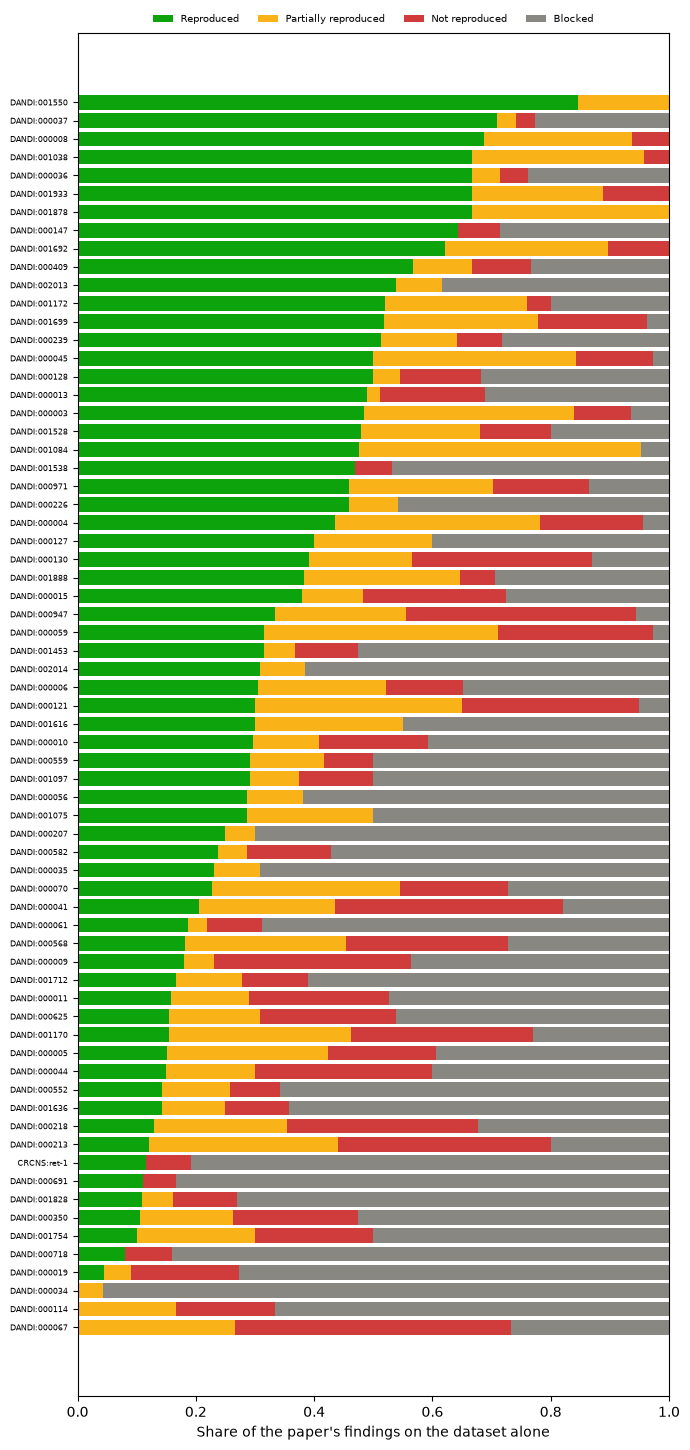

In [7]:
p = per.assign(share=per["reproduced"] / per["n"]).sort_values(["share", "n"])
fig, ax = plt.subplots(figsize=(7, 0.2 * len(p) + 1))
left = 0
for k in ORDER:
    frac = p[k] / p["n"]
    ax.barh(range(len(p)), frac, left=left, color=COLOUR[k], label=LABEL[k], height=0.8)
    left = left + frac
ax.set_yticks(range(len(p)), p["dataset"], fontsize=6); ax.set_xlim(0, 1)
ax.set_xlabel("Share of the paper's findings on the dataset alone")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, fontsize=7, frameon=False)
plt.tight_layout(); plt.savefig(OUT / "outcomes_by_dataset.png", dpi=200); plt.show()

In [8]:
g = per.groupby("catalystneuro")[ORDER + ["n", "findings_about_data"]].sum()
g.index = g.index.map({True: "Converted by CatalystNeuro", False: "Converted by others"})
g["datasets"] = per.groupby("catalystneuro").size().values
g["reproduced, of tested"] = (g["reproduced"] / g[ORDER[:3]].sum(axis=1)).map("{:.0%}".format)
g["findings per dataset"] = (g["findings_about_data"] / g["datasets"]).round(1)
numbers["by_converter"] = g.drop(columns=["reproduced, of tested"]).to_dict(orient="index")
g

,reproduced,partially_reproduced,not_reproduced,blocked,n,findings_about_data,datasets,"reproduced, of tested",findings per dataset
catalystneuro,,,,,,,,,
Converted by others,200,70,87,245,602,240,24,56%,10.0
Converted by CatalystNeuro,337,201,153,347,1038,565,44,49%,12.8


## 4. Verification

In [9]:
tiers = collections.Counter(a["tier"] for a in live)
disagreed = sum(1 for a in live for o in a["outcomes"] if o["disagreed"])
n_out = sum(len(a["outcomes"]) for a in live)
proposed = sum(1 for a in live for o in a["outcomes"] if o.get("proposed"))
numbers["verification"] = {"tiers": dict(tiers), "outcomes": n_out, "verifier_disagreed": disagreed,
                           "proposed_unverified": proposed}
print(f"Trust tiers of the current attempts: {dict(tiers)}")
print(f"An independent verifier disagreed at first with {disagreed} of {n_out} outcomes ({pct(disagreed, n_out)}); "
      f"{proposed} changes proposed after the last round are not yet verified.")

Trust tiers of the current attempts: {'agent_verified': 56, 'runs': 12}
An independent verifier disagreed at first with 96 of 1787 outcomes (5%); 1 changes proposed after the last round are not yet verified.


## 5. Findings about the data

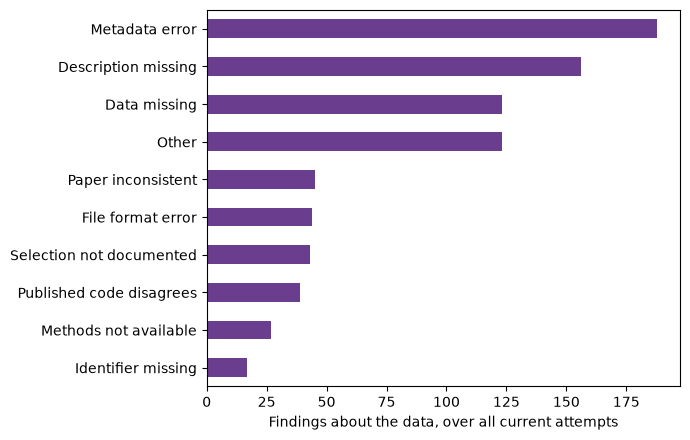

805 findings about the data; 68 of 68 datasets have at least one.


,findings
Metadata error,188
Description missing,156
Data missing,123
Other,123
Paper inconsistent,45
File format error,44
Selection not documented,43
Published code disagrees,39
Methods not available,27
Identifier missing,17


In [10]:
kinds = collections.Counter(f["kind"] for a in live for f in a["findings"])
numbers["findings"] = {"total": sum(kinds.values()), "kinds": dict(kinds),
                       "datasets_with_any": int((per["findings_about_data"] > 0).sum()), "datasets": len(per)}
s = pd.Series({bs.FINDING_KINDS.get(k, k): v for k, v in kinds.most_common()}, name="findings")
ax = s.iloc[::-1].plot.barh(color="#6a3d8f", figsize=(7, 0.35 * len(s) + 1))
ax.set_xlabel("Findings about the data, over all current attempts"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(OUT / "findings_by_kind.png", dpi=200); plt.show()
print(f"{sum(kinds.values())} findings about the data; {numbers['findings']['datasets_with_any']} of "
      f"{len(per)} datasets have at least one.")
s.to_frame()

## 6. Repeat attempts

A dataset is attempted again for one of three reasons: its data changed (a new version or the draft, after a
fix), its earlier attempt was deprecated and its claims re-read from the full text, or the protocol changed. Only
the first is a before and after of the data. Claims are matched by id; a claim that changed id is not compared.

In [11]:
by_pair = collections.defaultdict(list)
for a in sorted(attempts, key=lambda a: (a["date"], a["id"])):
    by_pair[(a["key"], a["paper"])].append(a)
moves, data_moves, rows = collections.Counter(), collections.Counter(), []
for (key, paper), seq in by_pair.items():
    for before, after in zip(seq, seq[1:]):
        b = {o["claim"]: o["outcome"] for o in before["outcomes"]}
        why = ("data changed" if after["dataset_version"] != before["dataset_version"]
               else "claims re-read" if before.get("deprecated") else "protocol changed")
        n = 0
        for o in after["outcomes"]:
            if o["claim"] in b:
                moves[(b[o["claim"]], o["outcome"])] += 1; n += 1
                if why == "data changed":
                    data_moves[(b[o["claim"]], o["outcome"])] += 1
        rows.append({"dataset": after["label"], "why": why, "before": before["id"], "after": after["id"],
                     "version before": before["dataset_version"], "version after": after["dataset_version"],
                     "claims compared": n, "findings before": len(before["findings"]),
                     "findings after": len(after["findings"]), "before deprecated": bool(before.get("deprecated"))})
numbers["repeats"] = {"pairs": len(rows), "why": dict(collections.Counter(r["why"] for r in rows)),
                      "transitions_all": {f"{a}->{b}": v for (a, b), v in moves.items()},
                      "transitions_data_changed": {f"{a}->{b}": v for (a, b), v in data_moves.items()}}

def matrix(counter):
    m = pd.DataFrame(0, index=[LABEL[k] for k in ORDER], columns=[LABEL[k] for k in ORDER])
    for (a, b), v in counter.items():
        m.loc[LABEL[a], LABEL[b]] = v
    return m.rename_axis(index="before", columns="after")

display(pd.DataFrame(rows))
print("Outcomes of the same claims, where the data changed between the attempts:")
display(matrix(data_moves))
print("All repeat attempts:")
matrix(moves)

,dataset,why,before,after,version before,version after,claims compared,findings before,findings after,before deprecated
0,DANDI:000582,claims re-read,000582-sargolini-2006-01,000582-sargolini-2006-02,0.251111.2151,0.251111.2151,3,5,13,True
1,DANDI:000006,claims re-read,000006-economo-2018-01,000006-economo-2018-02,0.220126.1855,0.220126.1855,9,7,10,True
2,DANDI:001754,data changed,001754-knierim-2000-01,001754-knierim-2000-02,0.260728.1352,draft,3,11,7,True
3,DANDI:001754,data changed,001754-knierim-2000-02,001754-knierim-2000-03,draft,0.260728.1352,3,7,14,True
4,DANDI:001636,data changed,001636-pasquereau-2013-01,001636-pasquereau-2013-02,0.260518.1819,draft,28,11,8,False
5,DANDI:001933,protocol changed,001933-chen-2026-01,001933-chen-2026-02,0.260825.1457,0.260825.1457,18,13,23,False
6,DANDI:000061,claims re-read,000061-girardeau-2017-01,000061-girardeau-2017-02,0.250624.0426,0.250624.0426,6,9,12,True
7,DANDI:000691,claims re-read,000691-scherrer-2023-01,000691-scherrer-2023-02,0.260827.1358,0.260827.1358,14,9,13,True
8,DANDI:000005,claims re-read,000005-yu-2016-01,000005-yu-2016-02,0.220126.1853,0.220126.1853,8,11,15,True


Outcomes of the same claims, where the data changed between the attempts:


after,Reproduced,Partially reproduced,Not reproduced,Blocked
before,,,,
Reproduced,5,0,1,0
Partially reproduced,0,3,0,0
Not reproduced,0,0,4,1
Blocked,0,0,1,19


All repeat attempts:


after,Reproduced,Partially reproduced,Not reproduced,Blocked
before,,,,
Reproduced,13,4,3,11
Partially reproduced,3,6,0,0
Not reproduced,0,1,7,3
Blocked,8,3,2,28


## Numbers for the manuscript

In [12]:
(OUT / "numbers.json").write_text(json.dumps(numbers, indent=1, default=str))
print(f"Wrote manuscript/out/numbers.json, per_dataset.csv and three figures, at commit {COMMIT}.")

Wrote manuscript/out/numbers.json, per_dataset.csv and three figures, at commit abc0e2880.
